<a href="https://colab.research.google.com/github/ANJARRIZANDI/simuteh-2330511035/blob/main/notebook/B5_praproses.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
%cd /content/simuteh-2330511035/notebook

!ls

/content/simuteh-2330511035/notebook
B1_lingkungan.ipynb   B3_histogram.ipynb  B5_praproses.ipynb
B2_citra_warna.ipynb  B4_penapisan.ipynb


In [7]:
import os
import sys
import subprocess

# 1. Memastikan repository tersedia
repo = "/content/simuteh-2330511035"

if not os.path.exists(repo):
    os.chdir("/content")
    subprocess.run(
        [
            "git", "clone",
            "https://github.com/ANJARRIZANDI/simuteh-2330511035.git"
        ],
        check=True
    )

# 2. Masuk ke folder notebook
os.chdir(repo + "/notebook")

print("Direktori aktif:", os.getcwd())

# 3. Memastikan file modul tersedia
assert os.path.exists("../src/utils_cv.py"), "utils_cv.py tidak ditemukan"
assert os.path.exists("../src/praproses.py"), "praproses.py tidak ditemukan"

# 4. Mengatur lokasi pencarian modul
sys.path.insert(0, os.path.abspath("../src"))

# 5. Import modul
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from utils_cv import baca, kontras_bercak
from praproses import praproses, simpan_param

print("Import modul berhasil!")

Direktori aktif: /content/simuteh-2330511035/notebook
Import modul berhasil!


In [9]:
# Kode 5.2 Evaluasi rangkaian praproses
from praproses import praproses, simpan_param

param = {"gamma": 1.0, "clahe_clip": 2.0, "penapis": "median", "kernel": 3}
simpan_param(param, "../hasil/param_praproses.json")
KANAL = 2                    # ganti sesuai kanal terbaik Anda di Bagian 2
                             # (indeks BGR: 0 = B, 1 = G, 2 = R)
label = pd.read_csv("../data/sintetis/label.csv")
baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img = baca(f"../data/sintetis/citra/{d.nama_file}")
    md = cv2.imread(f"../data/sintetis/mask_daun/{d.nama_file}", 0)
    mb = cv2.imread(f"../data/sintetis/mask_bercak/{d.nama_file}", 0)
    out = praproses(img, param)
    baris.append([d.kondisi_cahaya,
                  kontras_bercak(img[:, :, KANAL], md, mb),
                  kontras_bercak(out[:, :, KANAL], md, mb)])
evaluasi = pd.DataFrame(baris, columns=["kondisi", "KB_sebelum", "KB_sesudah"])
print(evaluasi.groupby("kondisi").mean().round(2))

                KB_sebelum  KB_sesudah
kondisi                               
bayangan              4.46        7.22
gelap                10.54       17.14
kontras_rendah        3.23        4.09
normal                8.93       10.42
terang                7.66        6.66


In [10]:
# Langkah 5.3: Uji bercak palsu pada kelas sehat

# Menggunakan parameter yang sama dengan Kode 5.2
KANAL = 2  # Kanal R

label = pd.read_csv("../data/sintetis/label.csv")

baris_sehat = []

for _, d in label[label.kelas == "sehat"].iterrows():

    # Membaca citra asli
    img = baca(f"../data/sintetis/citra/{d.nama_file}")

    # Membaca mask daun
    md = cv2.imread(
        f"../data/sintetis/mask_daun/{d.nama_file}", 0
    )

    # Melakukan praproses
    out = praproses(img, param)

    # Mengambil kanal terpilih sebelum dan sesudah
    kanal_sebelum = img[:, :, KANAL]
    kanal_sesudah = out[:, :, KANAL]

    # Menghitung simpangan baku pada area daun
    std_sebelum = kanal_sebelum[md > 0].std()
    std_sesudah = kanal_sesudah[md > 0].std()

    baris_sehat.append([
        d.nama_file,
        d.kondisi_cahaya,
        std_sebelum,
        std_sesudah
    ])

hasil_sehat = pd.DataFrame(
    baris_sehat,
    columns=[
        "nama",
        "kondisi",
        "std_sebelum",
        "std_sesudah"
    ]
)

# Rata-rata berdasarkan kondisi cahaya
print(
    hasil_sehat.groupby("kondisi")[
        ["std_sebelum", "std_sesudah"]
    ].mean().round(2)
)


                std_sebelum  std_sesudah
kondisi                                 
bayangan              13.41        10.17
gelap                 10.73         7.65
kontras_rendah        10.90        10.69
normal                11.41         9.83
terang                12.92        13.08


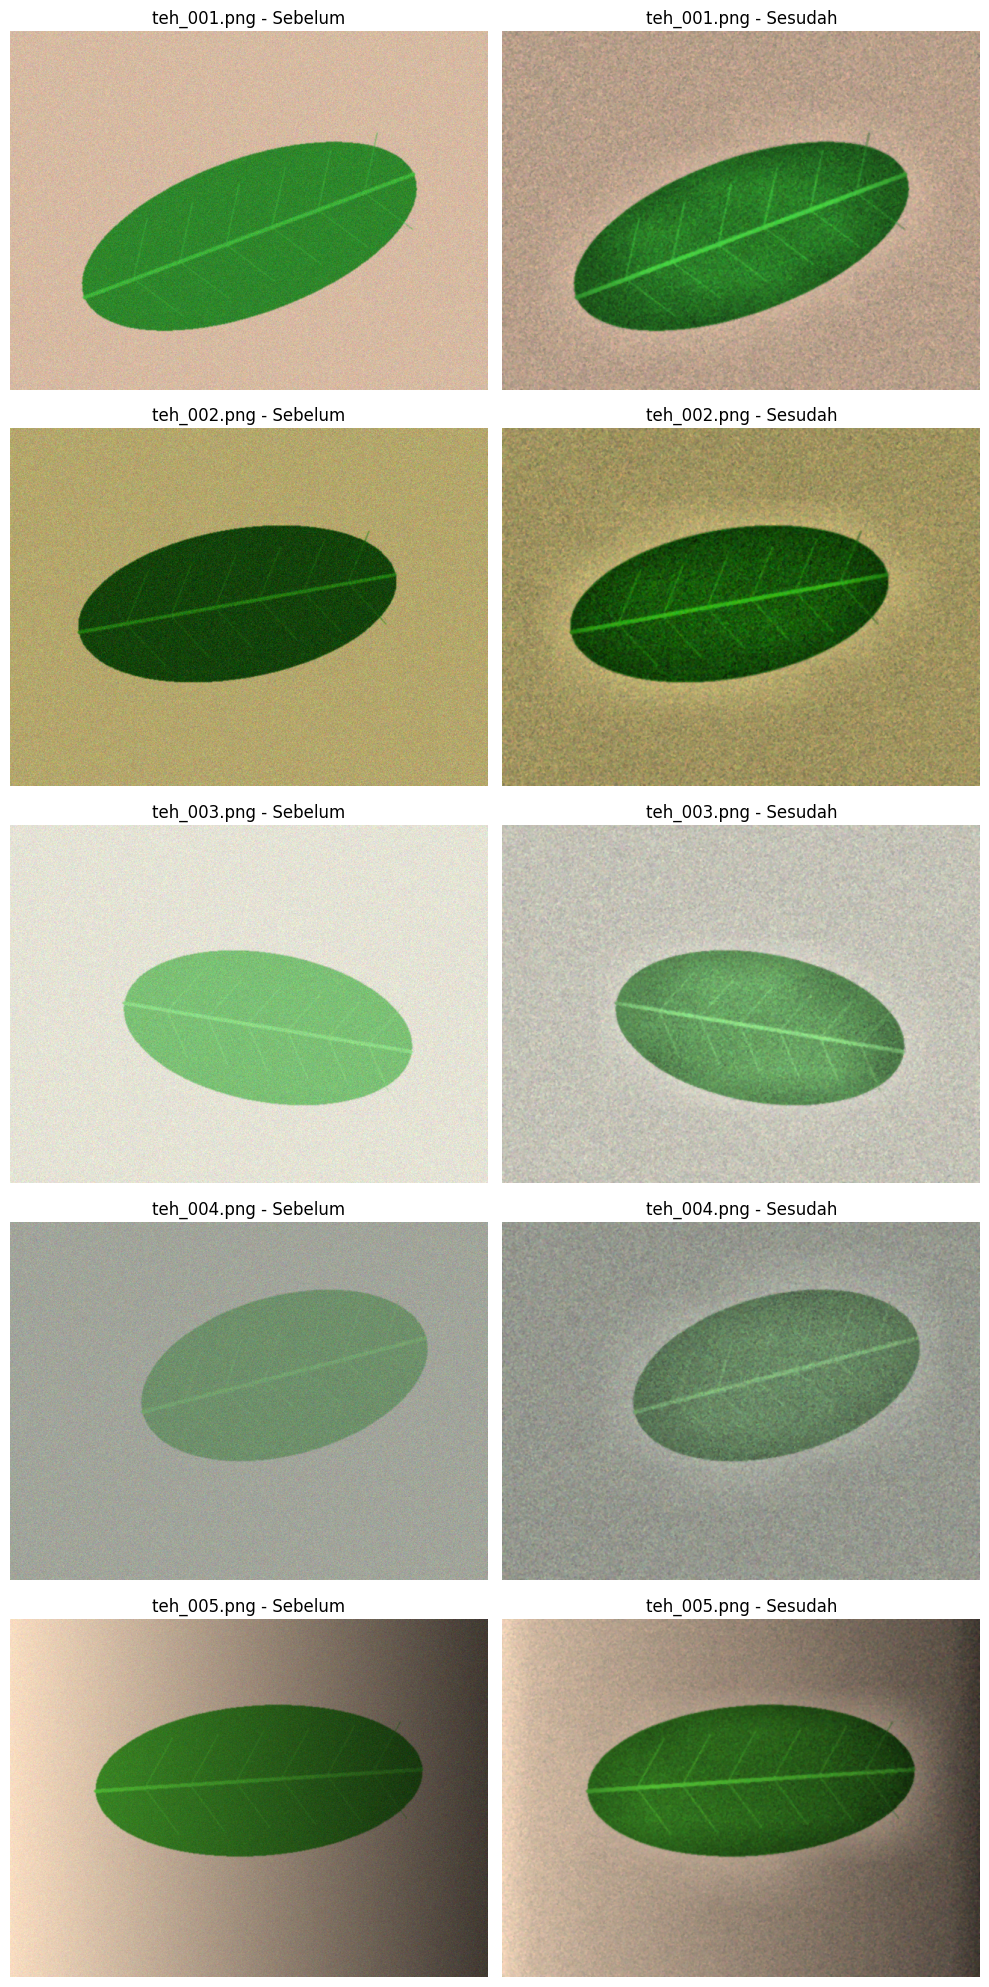

In [11]:
# Menampilkan perbandingan sebelum dan sesudah praproses

kondisi_pilihan = ["normal", "gelap", "terang",
                   "kontras_rendah", "bayangan"]

fig, axes = plt.subplots(5, 2, figsize=(10, 20))

for i, kondisi in enumerate(kondisi_pilihan):

    d = label[
        (label.kelas == "sehat") &
        (label.kondisi_cahaya == kondisi)
    ].iloc[0]

    img = baca(f"../data/sintetis/citra/{d.nama_file}")
    out = praproses(img, param)

    axes[i, 0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    axes[i, 0].set_title(f"{d.nama_file} - Sebelum")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(cv2.cvtColor(out, cv2.COLOR_BGR2RGB))
    axes[i, 1].set_title(f"{d.nama_file} - Sesudah")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.savefig(
    "../hasil/b5_uji_bercak_palsu.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [12]:
hasil_sehat.to_csv(
    "../hasil/b5_uji_bercak_palsu.csv",
    index=False
)

print("Hasil pengujian berhasil disimpan.")

Hasil pengujian berhasil disimpan.


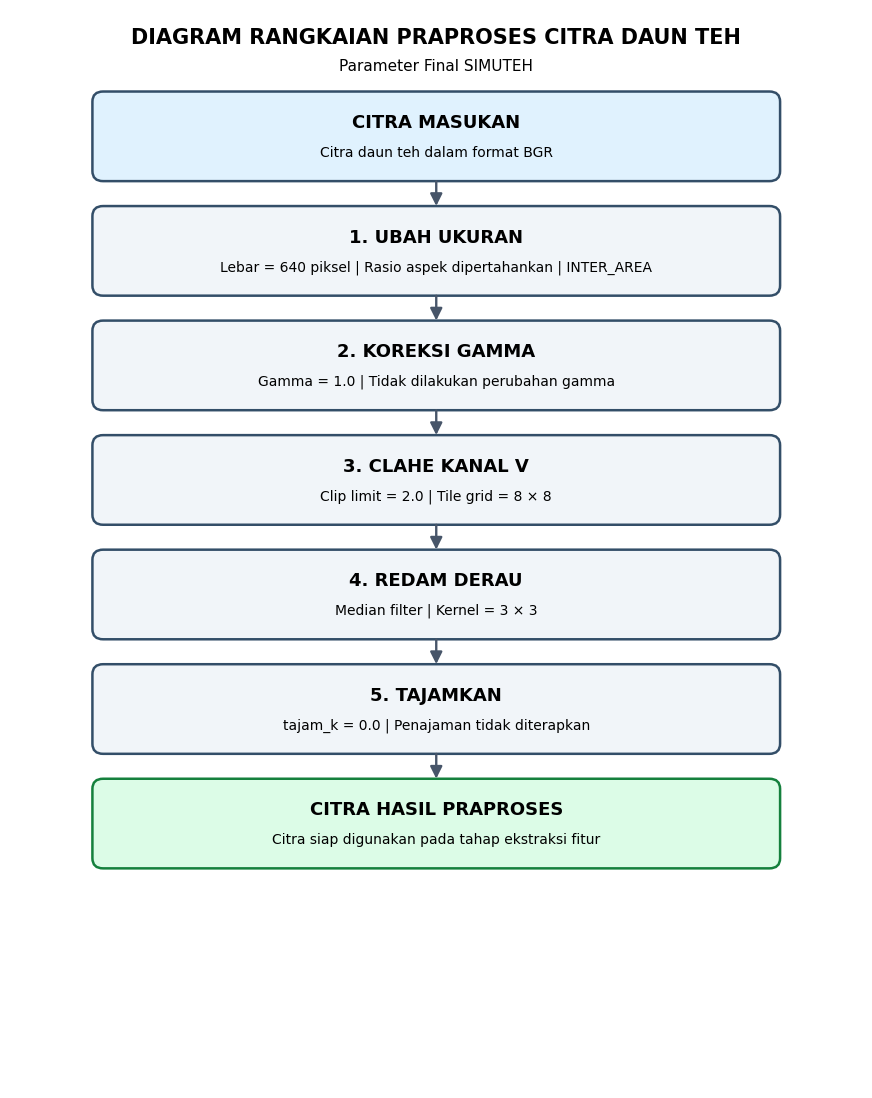

Diagram berhasil disimpan di: ../hasil/diagram_rangkaian_praproses.png


In [13]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
import os

# Membuat area gambar
fig, ax = plt.subplots(figsize=(11, 14))
ax.set_xlim(0, 12)
ax.set_ylim(0, 16)
ax.axis("off")

# Fungsi membuat kotak diagram
def buat_kotak(y, judul, keterangan,
               warna="#F1F5F9", garis="#334E68"):

    kotak = FancyBboxPatch(
        (1.2, y), 9.6, 1.25,
        boxstyle="round,pad=0.04,rounding_size=0.15",
        linewidth=1.8,
        edgecolor=garis,
        facecolor=warna
    )

    ax.add_patch(kotak)

    ax.text(
        6, y + 0.82, judul,
        ha="center", va="center",
        fontsize=13, fontweight="bold"
    )

    ax.text(
        6, y + 0.38, keterangan,
        ha="center", va="center",
        fontsize=10
    )


# Fungsi membuat panah
def buat_panah(y_awal, y_akhir):
    panah = FancyArrowPatch(
        (6, y_awal),
        (6, y_akhir),
        arrowstyle="-|>",
        mutation_scale=18,
        linewidth=1.7,
        color="#475569"
    )
    ax.add_patch(panah)


# Judul diagram
ax.text(
    6, 15.5,
    "DIAGRAM RANGKAIAN PRAPROSES CITRA DAUN TEH",
    ha="center",
    fontsize=15,
    fontweight="bold"
)

ax.text(
    6, 15.1,
    "Parameter Final SIMUTEH",
    ha="center",
    fontsize=11
)


# 1. Citra masukan
buat_kotak(
    13.5,
    "CITRA MASUKAN",
    "Citra daun teh dalam format BGR",
    "#E0F2FE"
)
buat_panah(13.5, 13.05)


# 2. Resize
buat_kotak(
    11.8,
    "1. UBAH UKURAN",
    "Lebar = 640 piksel | Rasio aspek dipertahankan | INTER_AREA"
)
buat_panah(11.8, 11.35)


# 3. Gamma
buat_kotak(
    10.1,
    "2. KOREKSI GAMMA",
    "Gamma = 1.0 | Tidak dilakukan perubahan gamma"
)
buat_panah(10.1, 9.65)


# 4. CLAHE
buat_kotak(
    8.4,
    "3. CLAHE KANAL V",
    "Clip limit = 2.0 | Tile grid = 8 × 8"
)
buat_panah(8.4, 7.95)


# 5. Denoising
buat_kotak(
    6.7,
    "4. REDAM DERAU",
    "Median filter | Kernel = 3 × 3"
)
buat_panah(6.7, 6.25)


# 6. Sharpening
buat_kotak(
    5.0,
    "5. TAJAMKAN",
    "tajam_k = 0.0 | Penajaman tidak diterapkan"
)
buat_panah(5.0, 4.55)


# 7. Hasil akhir
buat_kotak(
    3.3,
    "CITRA HASIL PRAPROSES",
    "Citra siap digunakan pada tahap ekstraksi fitur",
    "#DCFCE7",
    "#15803D"
)


# Simpan diagram
os.makedirs("../hasil", exist_ok=True)

lokasi = "../hasil/diagram_rangkaian_praproses.png"

plt.savefig(
    lokasi,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Diagram berhasil disimpan di:", lokasi)